In [1]:
import subprocess, sys, time, warnings, os
warnings.filterwarnings('ignore')
t0 = time.time()
subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'opacus'], check=True)

import torch, torchvision, numpy as np, matplotlib, opacus
torch.manual_seed(42); np.random.seed(42)
torch.set_num_threads(os.cpu_count())
device = torch.device('cpu')
print(f"torch {torch.__version__} | torchvision {torchvision.__version__} | opacus {opacus.__version__} | numpy {np.__version__} | matplotlib {matplotlib.__version__}")
print("Device:", device, "| GPU available (unused by design):", torch.cuda.is_available())
print(f"Elapsed: {time.time()-t0:.1f}s")

torch 2.14.1+cu130 | torchvision 0.29.1+cu130 | opacus 1.6.0 | numpy 2.4.6 | matplotlib 3.10.0
Device: cpu | GPU available (unused by design): True
Elapsed: 16.7s


In [5]:
import time, torch, torch.nn as nn, torch.nn.functional as F, numpy as np
from torchvision import datasets
from torch.utils.data import TensorDataset, DataLoader
from opacus import PrivacyEngine
t0 = time.time()
SEED, BS, EPOCHS, DELTA, CLIP, LR = 42, 256, 3, 1e-5, 1.0, 0.1

# ---- Data: first 20,000 train images (interpretation: Flag A default), full 10k test
tr = datasets.MNIST('./data', train=True, download=True)
te = datasets.MNIST('./data', train=False, download=True)
prep = lambda x: ((x.float()/255.) - 0.1307)/0.3081
Xtr, ytr = prep(tr.data[:20000]).unsqueeze(1), tr.targets[:20000]
Xte, yte = prep(te.data).unsqueeze(1), te.targets
train_ds = TensorDataset(Xtr, ytr)
def loader(): return DataLoader(train_ds, batch_size=BS, shuffle=True)
test_loader = DataLoader(TensorDataset(Xte, yte), batch_size=1000)

# ---- Small CNN with GroupNorm (Opacus-compatible)
class CNN(nn.Module):
    def __init__(s):
        super().__init__()
        s.c1, s.g1 = nn.Conv2d(1,16,3), nn.GroupNorm(4,16)
        s.c2, s.g2 = nn.Conv2d(16,32,3), nn.GroupNorm(8,32)
        s.f1, s.f2 = nn.Linear(32*5*5,64), nn.Linear(64,10)
    def forward(s,x):
        x = F.max_pool2d(F.relu(s.g1(s.c1(x))),2)
        x = F.max_pool2d(F.relu(s.g2(s.c2(x))),2)
        return s.f2(F.relu(s.f1(x.flatten(1))))

def make_model():
    torch.manual_seed(SEED); np.random.seed(SEED)
    m = CNN(); return m, torch.optim.SGD(m.parameters(), lr=LR, momentum=0.9)

def train_epoch(m, opt, dl):
    m.train()
    for x,y in dl:
        opt.zero_grad(); F.cross_entropy(m(x),y).backward(); opt.step()

@torch.no_grad()
def accuracy(m, dl=test_loader):
    m.eval(); c = 0
    for x,y in dl: c += (m(x).argmax(1)==y).sum().item()
    return 100*c/len(dl.dataset)

# ---- Task 1: baseline
model_base, opt = make_model()
dl = loader()
for _ in range(EPOCHS): train_epoch(model_base, opt, dl)
acc_base = accuracy(model_base)
print(f"Baseline (no DP) : test accuracy {acc_base:.1f} %")
print(f"Task 1 time: {time.time()-t0:.0f}s")

# ---- Task 2: DP models for target eps = 10, 5, 1
results, dp_models = {}, {}
for eps in [10.0, 5.0, 1.0]:
    m, o = make_model()
    pe = PrivacyEngine()
    m, o, dl = pe.make_private_with_epsilon(module=m, optimizer=o, data_loader=loader(),
              target_epsilon=eps, target_delta=DELTA, epochs=EPOCHS, max_grad_norm=CLIP)
    for _ in range(EPOCHS): train_epoch(m, o, dl)
    results[eps] = (accuracy(m), pe.get_epsilon(DELTA)); dp_models[eps] = m
    print(f"  eps={eps} done, sigma={o.noise_multiplier:.3f}, t={time.time()-t0:.0f}s")

print("\nTARGET_EPS DELTA CLIP(C) EPOCHS TEST_ACC EPS_SPENT")
print("-"*61)
for eps,(a,es) in results.items():
    print(f"{eps:<10} {DELTA:<6} {CLIP:<7} {EPOCHS:<6} {a:5.1f} %   {es:.2f}")
print("-"*61)
print(f"Accuracy cost of strongest privacy (eps = 1) : {results[1.0][0]-acc_base:+.1f} %")


Baseline (no DP) : test accuracy 97.6 %
Task 1 time: 17s
  eps=10.0 done, sigma=0.491, t=63s
  eps=5.0 done, sigma=0.619, t=108s
  eps=1.0 done, sigma=1.104, t=154s

TARGET_EPS DELTA CLIP(C) EPOCHS TEST_ACC EPS_SPENT
-------------------------------------------------------------
10.0       1e-05  1.0     3       95.1 %   9.99
5.0        1e-05  1.0     3       94.9 %   5.00
1.0        1e-05  1.0     3       94.0 %   1.00
-------------------------------------------------------------
Accuracy cost of strongest privacy (eps = 1) : -3.6 %
Elapsed: 154s


In [6]:
import time
t0 = time.time()

# ---- Task 3: fixed noise_multiplier = 1.1, record eps after each epoch
m3, o3 = make_model()
pe3 = PrivacyEngine()
m3, o3, dl3 = pe3.make_private(module=m3, optimizer=o3, data_loader=loader(),
              noise_multiplier=1.1, max_grad_norm=CLIP)
eps_epoch = []
for ep in range(EPOCHS):
    train_epoch(m3, o3, dl3)
    eps_epoch.append(pe3.get_epsilon(DELTA))

print("FIXED noise_multiplier = 1.1")
print("EPOCH EPSILON_SPENT")
print("-"*21)
for i, e in enumerate(eps_epoch, 1):
    print(f"{i:<5} {e:.2f}")
print("-"*21)

# ---- Task 4: membership check (mean max-softmax confidence)
@torch.no_grad()
def mean_conf(m, X):
    m.eval(); c = []
    for i in range(0, len(X), 1000):
        c.append(F.softmax(m(X[i:i+1000]), 1).max(1).values)
    return torch.cat(c).mean().item()

rows = [("Baseline", model_base), ("DP (eps=1)", dp_models[1.0])]
print("\nMEMBERSHIP CHECK (mean max-softmax confidence)")
print(f"{'MODEL':<11} {'TRAIN':<7} {'TEST':<7} GAP")
print("-"*35)
conf = {}
for name, m in rows:
    tr_c, te_c = mean_conf(m, Xtr), mean_conf(m, Xte)
    conf[name] = (tr_c, te_c, tr_c - te_c)
    print(f"{name:<11} {tr_c:.3f}   {te_c:.3f}   {tr_c-te_c:.3f}")
print("-"*35)
print(f"Elapsed: {time.time()-t0:.0f}s")

FIXED noise_multiplier = 1.1
EPOCH EPSILON_SPENT
---------------------
1     0.66
2     0.85
3     1.01
---------------------

MEMBERSHIP CHECK (mean max-softmax confidence)
MODEL       TRAIN   TEST    GAP
-----------------------------------
Baseline    0.978   0.976   0.003
DP (eps=1)  0.968   0.971   -0.002
-----------------------------------
Elapsed: 50s


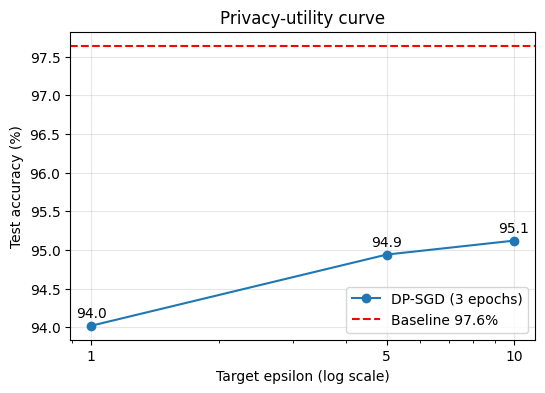

Plot saved : accuracy_vs_epsilon.png
EPS  TEST_ACC
1.0  94.0
5.0  94.9
10.0 95.1


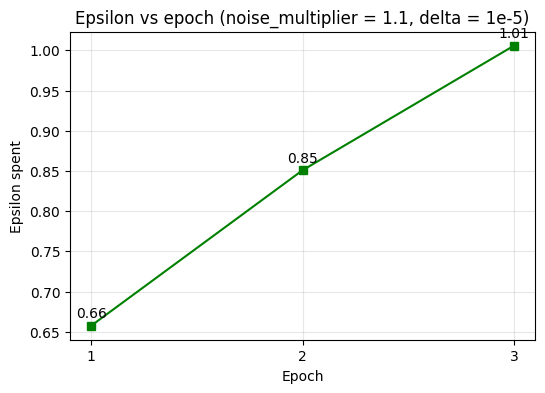

Plot saved : epsilon_vs_epoch.png
EPOCH EPSILON_SPENT
1     0.66
2     0.85
3     1.01


[None, None, None]

In [8]:
import matplotlib.pyplot as plt
import time
t0 = time.time()

# ---- Task 5a: accuracy vs eps (privacy-utility curve)
eps_list = sorted(results.keys())
accs = [results[e][0] for e in eps_list]
plt.figure(figsize=(6,4))
plt.plot(eps_list, accs, 'o-', label='DP-SGD (3 epochs)')
plt.axhline(acc_base, color='r', ls='--', label=f'Baseline {acc_base:.1f}%')
for e,a in zip(eps_list, accs): plt.annotate(f"{a:.1f}", (e,a), textcoords='offset points', xytext=(0,6), ha='center')
plt.xscale('log'); plt.xticks(eps_list, [str(int(e)) for e in eps_list])
plt.xlabel('Target epsilon (log scale)'); plt.ylabel('Test accuracy (%)')
plt.title('Privacy-utility curve'); plt.grid(alpha=.3); plt.legend()
plt.savefig('accuracy_vs_epsilon.png', dpi=150, bbox_inches='tight'); plt.show()
print("Plot saved : accuracy_vs_epsilon.png")
print("EPS  TEST_ACC"); [print(f"{e:<4} {a:.1f}") for e,a in zip(eps_list, accs)]

# ---- Task 5b: epsilon vs epoch (noise_multiplier = 1.1)
plt.figure(figsize=(6,4))
plt.plot(range(1, EPOCHS+1), eps_epoch, 's-', color='g')
for i,e in enumerate(eps_epoch,1): plt.annotate(f"{e:.2f}", (i,e), textcoords='offset points', xytext=(0,6), ha='center')
plt.xticks(range(1, EPOCHS+1)); plt.xlabel('Epoch'); plt.ylabel('Epsilon spent')
plt.title('Epsilon vs epoch (noise_multiplier = 1.1, delta = 1e-5)'); plt.grid(alpha=.3)
plt.savefig('epsilon_vs_epoch.png', dpi=150, bbox_inches='tight'); plt.show()
print("Plot saved : epsilon_vs_epoch.png")
print("EPOCH EPSILON_SPENT"); [print(f"{i:<5} {e:.2f}") for i,e in enumerate(eps_epoch,1)]

In [9]:
print("\n===== PART A: Accuracy at Different Privacy Budgets =====")
print(f"Baseline (no DP) : test accuracy {acc_base:.1f} %")
print("TARGET_EPS DELTA CLIP(C) EPOCHS TEST_ACC EPS_SPENT")
print("-"*61)
for e in [10.0, 5.0, 1.0]:
    a, es = results[e]
    print(f"{e:<10} {DELTA:<6} {CLIP:<7} {EPOCHS:<6} {a:5.1f} %   {es:.2f}")
print("-"*61)
print(f"Accuracy cost of strongest privacy (eps = 1) : {results[1.0][0]-acc_base:+.1f} %")
print("Plot saved : accuracy_vs_epsilon.png")

print("\n===== PART B: Privacy Accounting and Membership Check =====")
print("FIXED noise_multiplier = 1.1")
print("EPOCH EPSILON_SPENT"); print("-"*21)
for i,e in enumerate(eps_epoch,1): print(f"{i:<5} {e:.2f}")
print("-"*21)
print("MEMBERSHIP CHECK (mean max-softmax confidence)")
print(f"{'MODEL':<11} {'TRAIN':<7} {'TEST':<7} GAP"); print("-"*35)
for n,(a,b,g) in conf.items(): print(f"{n:<11} {a:.3f}   {b:.3f}   {g:.3f}")
print("-"*35)
print(f"Recommended eps : 1 (only {results[1.0][0]-acc_base:+.1f} % accuracy, strongest privacy)")
print(f"Elapsed: {time.time()-t0:.0f}s")


===== PART A: Accuracy at Different Privacy Budgets =====
Baseline (no DP) : test accuracy 97.6 %
TARGET_EPS DELTA CLIP(C) EPOCHS TEST_ACC EPS_SPENT
-------------------------------------------------------------
10.0       1e-05  1.0     3       95.1 %   9.99
5.0        1e-05  1.0     3       94.9 %   5.00
1.0        1e-05  1.0     3       94.0 %   1.00
-------------------------------------------------------------
Accuracy cost of strongest privacy (eps = 1) : -3.6 %
Plot saved : accuracy_vs_epsilon.png

===== PART B: Privacy Accounting and Membership Check =====
FIXED noise_multiplier = 1.1
EPOCH EPSILON_SPENT
---------------------
1     0.66
2     0.85
3     1.01
---------------------
MEMBERSHIP CHECK (mean max-softmax confidence)
MODEL       TRAIN   TEST    GAP
-----------------------------------
Baseline    0.978   0.976   0.003
DP (eps=1)  0.968   0.971   -0.002
-----------------------------------
Recommended eps : 1 (only -3.6 % accuracy, strongest privacy)
Elapsed: 28s
